# Phase 0B | Recover Optogenetic Stimulation Metadata
### Human hippocampal DANDI 001132 + Andrews et al. source code

**Goal:** Determine whether real light ON/OFF event timestamps, light intensity/duration, and neural response labels can be linked reliably across DANDI NWB recordings and the authors' publicly released analysis files. **No AI training takes place in this notebook.**

**Evidence categories (do not mix them):**
- **Observed in NWB:** file structure and metadata, not inferred labels.
- **Authors' code:** example stimulation logs and experimental protocol definitions, which are **not** automatically labels for a DANDI sample.
- **Processed statistics:** pre/stim/post activity summaries; useful for reproduction, but not raw synchronized time series.

Dataset: https://dandiarchive.org/dandiset/001132  
Study: https://doi.org/10.1038/s41593-024-01782-5  
Authors' repository: https://github.com/braingeneers/AndrewsGengVoitiukEtAl_SourceCode

**Kaggle settings:** Internet **ON**; accelerator **None** (CPU). Input **not required** by default. The notebook downloads only the authors' GitHub ZIP (~35 MB), the DANDI manifest, and *remote NWB metadata*. It **never downloads full NWB recordings**.


## 1. Install metadata-streaming support

Kaggle already includes pandas/numpy/requests/h5py. `remfile` lets h5py read HDF5 metadata using HTTP byte ranges.

In [1]:
%pip -q install remfile

Note: you may need to restart the kernel to use updated packages.


## 2. Settings

Default scans **one NWB recording per HcKCR1 slice** (up to 8), not 69 full files. To check every file later, set `SCAN_ALL_NWB = True`, but expect a much longer network run. Only metadata is accessed.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from IPython.display import display
import io, os, re, json, zipfile, traceback
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

DANDISET = "001132"
VERSION = "0.241130.1903"  # Fixed, reproducible DANDI version
API = "https://api.dandiarchive.org/api"
SCAN_ALL_NWB = False           # Change to True for all 69 (slow)
MAX_NWB_PROBES = 8             # One small recording from each inhibitory slice
REPO_ZIP_OVERRIDE = ""          # Optional existing GitHub ZIP filepath
MAX_REPO_DOWNLOAD_MB = 95

OUT = Path('/kaggle/working/phase0b_optogenetics') if Path('/kaggle/working').exists() else Path('phase0b_optogenetics')
OUT.mkdir(parents=True, exist_ok=True)
print('Writing audit files to:', OUT.resolve())
print('No training, no raw NWB downloads. DANDI version:', VERSION)

Writing audit files to: /kaggle/working/phase0b_optogenetics
No training, no raw NWB downloads. DANDI version: 0.241130.1903


## 3. Load the authors' repository (automatic; no Kaggle input normally needed)

The notebook first looks for a previously uploaded ZIP, otherwise downloads the official public repository. If GitHub is blocked in Kaggle, upload your original GitHub ZIP as a Kaggle Input and set `REPO_ZIP_OVERRIDE` to its full path.

In [3]:
def locate_repo_zip():
    if REPO_ZIP_OVERRIDE:
        p = Path(REPO_ZIP_OVERRIDE)
        if not p.exists():
            raise FileNotFoundError(f'REPO_ZIP_OVERRIDE not found: {p}')
        return p
    # Optional local/uploaded ZIP takes precedence.
    for base in (Path('/kaggle/input'), Path('/mnt/data'), Path.cwd()):
        if base.exists():
            matches = list(base.rglob('AndrewsGengVoitiukEtAl_SourceCode-master.zip'))
            if matches:
                return matches[0]
    url_candidates = [
        'https://github.com/braingeneers/AndrewsGengVoitiukEtAl_SourceCode/archive/refs/heads/master.zip',
        'https://codeload.github.com/braingeneers/AndrewsGengVoitiukEtAl_SourceCode/zip/refs/heads/master',
    ]
    target = OUT / 'authors_repository.zip'
    last_error = None
    for url in url_candidates:
        try:
            total = 0
            with requests.get(url, stream=True, timeout=(20,120)) as r:
                r.raise_for_status()
                with target.open('wb') as f:
                    for chunk in r.iter_content(chunk_size=1024*1024):
                        if chunk:
                            total += len(chunk)
                            if total > MAX_REPO_DOWNLOAD_MB * 1024 * 1024:
                                raise ValueError('Unexpected large repository download')
                            f.write(chunk)
            with zipfile.ZipFile(target) as check:
                if check.testzip() is not None:
                    raise ValueError('Repository ZIP is corrupt')
            return target
        except Exception as exc:
            last_error = repr(exc)
            if target.exists(): target.unlink()
    raise RuntimeError('Cannot download the GitHub source ZIP. Attach the authors repo as a Kaggle Input, set REPO_ZIP_OVERRIDE, rerun. Last error: ' + str(last_error))

REPO_PATH = locate_repo_zip()
repo = zipfile.ZipFile(REPO_PATH)
repo_names = repo.namelist()
print('Authors ZIP:', REPO_PATH, f'({len(repo_names)} entries)')
print('Experiment-specific full logs:', sum(n.endswith('_opto_stim_log.csv') and 'example' not in n.lower() for n in repo_names))

Authors ZIP: /kaggle/working/phase0b_optogenetics/authors_repository.zip (179 entries)
Experiment-specific full logs: 0


## 4. Inventory all CSV evidence

`pre / stim / post` recordings are useful response summaries, but their `Trial` identifiers are local to each CSV. **Do not sum rows as if they were independent patients or independent experiments.** `amp` files are kept separate from files explicitly named `fr`.

In [4]:
all_csv = [n for n in repo_names if n.lower().endswith('.csv')]
records = []
for name in all_csv:
    path = name.split('/', 1)[-1]
    kind = ('processed_response_statistics' if '/data/statistics/' in name
            else 'stimulation_log_example' if '_opto_stim_log.csv' in name or name.endswith('example_opto_log.csv')
            else 'calibration' if '/calibration' in name.lower()
            else 'other_csv')
    if kind == 'processed_response_statistics':
        metric_hint = ('firing_rate' if name.lower().endswith('fr.csv') else
                       'amplitude_or_other' if name.lower().endswith('amp.csv') else 'unspecified')
    else:
        metric_hint = ''
    try:
        df = pd.read_csv(io.BytesIO(repo.read(name)))
        rec = dict(file=path, evidence_type=kind, metric_hint_from_filename=metric_hint,
                   rows=len(df), columns='|'.join(map(str, df.columns)),
                   n_local_trials=int(df.Trial.nunique()) if 'Trial' in df else None,
                   n_local_neuron_ids=int(df.Neuron_ID.nunique()) if 'Neuron_ID' in df else None,
                   conditions='|'.join(sorted(df.Condition.astype(str).unique())) if 'Condition' in df else '')
    except Exception as exc:
        rec = dict(file=path, evidence_type=kind, metric_hint_from_filename=metric_hint, error=repr(exc))
    records.append(rec)
repo_inventory = pd.DataFrame(records)
repo_inventory.to_csv(OUT/'authors_repository_csv_inventory.csv', index=False)
print('CSV files:', len(repo_inventory))
print(repo_inventory.groupby(['evidence_type','metric_hint_from_filename'],dropna=False).size().to_string())
print('\nEXAMPLE logs (do not assign them to DANDI files):')
display(repo_inventory[repo_inventory.evidence_type == 'stimulation_log_example'][['file','rows','columns']])
print('\nPROCESSED stats overview:')
display(repo_inventory[repo_inventory.evidence_type == 'processed_response_statistics'][['file','metric_hint_from_filename','rows','n_local_trials','conditions']].head(30))

CSV files: 47
evidence_type                  metric_hint_from_filename
calibration                                                 14
other_csv                                                    5
processed_response_statistics  amplitude_or_other           13
                               firing_rate                   9
                               unspecified                   4
stimulation_log_example                                      2

EXAMPLE logs (do not assign them to DANDI files):


,file,rows,columns
0,Optogenetic_Control/20230404T172401-2023_04_04...,15,time (sec)|intensity_fraction|initial_delay (f...
43,experiment_implementer/files/opto/logs/example...,5,time (sec)|intensity_fraction|initial_delay (f...



PROCESSED stats overview:


,file,metric_hint_from_filename,rows,n_local_trials,conditions
14,data/statistics/formatted_data Hc110723_hckcr1...,unspecified,255,5.0,post|pre|stim
15,data/statistics/formatted_data Hc110723_hckcr1...,amplitude_or_other,255,5.0,post|pre|stim
16,data/statistics/formatted_data Hc110723_hckcr1...,unspecified,855,5.0,post|pre|stim
17,data/statistics/formatted_data Hc110723_hckcr1...,amplitude_or_other,855,5.0,post|pre|stim
18,data/statistics/formatted_data Hc112823_avv9hc...,amplitude_or_other,6840,10.0,post|pre|stim
19,data/statistics/formatted_data Hc112823_avv9hc...,firing_rate,6840,10.0,post|pre|stim
20,data/statistics/formatted_data Hc112823_avv9hc...,amplitude_or_other,6360,10.0,post|pre|stim
21,data/statistics/formatted_data Hc112823_avv9hc...,firing_rate,6360,10.0,post|pre|stim
22,data/statistics/formatted_data Hc120523_aav9hc...,amplitude_or_other,690,10.0,post|pre|stim
23,data/statistics/formatted_data Hc120523_aav9hc...,firing_rate,690,10.0,post|pre|stim


## 5. Inspect stimulation-log schemas and protocol-source references

The public example logs are **not necessarily synchronized** with DANDI NWB files. Experiment templates show how logs and raw HDF5 recordings were named. We collect cited `.raw.h5` paths to aid requests for original metadata; these are **hints only, not verified mappings**.

In [5]:
examples = []
for n in repo_names:
    if n.endswith('_opto_stim_log.csv') or n.endswith('example_opto_log.csv'):
        frame = pd.read_csv(io.BytesIO(repo.read(n)))
        frame.insert(0,'example_log_filename', n.split('/')[-1])
        examples.append(frame)
if examples:
    example_logs = pd.concat(examples, ignore_index=True)
    example_logs.to_csv(OUT/'example_optogenetic_logs_NOT_DANDI_LABELS.csv',index=False)
    display(example_logs.head(10))
    print('Distinct intensity fractions in EXAMPLES:', sorted(example_logs.intensity_fraction.dropna().unique()) if 'intensity_fraction' in example_logs else 'not given')
else:
    print('No example logs included. Do not fabricate actions.')

raw_refs=[]
for n in repo_names:
    if not n.endswith('.ipynb'): continue
    try:
        notebook=json.loads(repo.read(n))
        for cell_idx,cell in enumerate(notebook.get('cells',[])):
            s=''.join(cell.get('source',[]))
            for path in set(re.findall(r'[A-Za-z0-9_./\\-]+\.raw\.h5',s)):
                raw_refs.append(dict(notebook=n.split('/')[-1], cell_number=cell_idx, cited_raw_h5=path))
    except Exception: continue
raw_reference_table=pd.DataFrame(raw_refs).drop_duplicates() if raw_refs else pd.DataFrame(columns=['notebook','cell_number','cited_raw_h5'])
raw_reference_table.to_csv(OUT/'author_notebook_original_raw_h5_references_UNVERIFIED.csv',index=False)
print('Distinct raw H5 filenames cited:', raw_reference_table.cited_raw_h5.nunique())
display(raw_reference_table.head(15))

raw_log_code = [n for n in repo_names if n.endswith('optogenetics_enviroment.py')]
(OUT/'critical_alignment_notes.txt').write_text(
    'Author example logs: intensity_fraction and duration in frames are commands, not synchronized NWB light events.\n'
    'Original figure notebook uses ephys.load_gpio_maxwell(rec_path) on .raw.h5 recordings.\n'
    'Different experiment implementations may use different frame or time units; verify per experiment.\n'
    'Matching by a similar-looking basename or date is NOT a validated join.\n'
    'Need recording UUID/raw file -> NWB asset -> experiment log -> donor/slice mapping.\n'
    'Relevant implementations: '+', '.join(raw_log_code)+'\n'
)


,example_log_filename,time (sec),intensity_fraction,initial_delay (frames),on_duration (frames),off_duration (frames),notes,use_maxwell,delta_t (sec)
0,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,22.648200
1,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,20.014760
2,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,20.011855
3,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,20.012011
4,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,20.012355
5,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,20.012286
6,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,20.013546
7,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,20.009961
8,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,20.019654
9,20230404T172401-2023_04_04_example_opto_stim_l...,1.680654e+09,0.5,0,200000,4000,NaN,True,20.012762


Distinct intensity fractions in EXAMPLES: [np.float64(0.5)]
Distinct raw H5 filenames cited: 18


,notebook,cell_number,cited_raw_h5
0,amp_comp.ipynb,7,2023_04_04_hc328_hckcr1-2_3.raw.h5
1,amp_comp.ipynb,9,/home/kang/disk/Opto/20230510_ucsf/hc52_chip18...
2,closed_loop_raster.ipynb,1,/home/kang/disk/Opto/20230510_ucsf/hc52_chip18...
3,closed_loop_raster.ipynb,1,hc52_chip18790_rec51023_1.raw.h5
4,closed_loop_raster.ipynb,2,2023_04_04_hc328_hckcr1-2_3.raw.h5
5,closed_loop_raster.ipynb,2,/home/kang/disk/Opto/20230402_ucsf/2023_04_04_...
6,figure1_footprints_post.ipynb,1,/disk/Opto/20230402_ucsf/2023_04_02_hc328_spt/...
7,figure1_footprints_post.ipynb,1,/disk/Opto/20221102_ucsf/hc11.1_plated-11.1_ch...
8,figure1_footprints_post.ipynb,1,/disk/Opto/20230402_ucsf/2023_04_02_hc328_spt/...
9,figure4_intensity.ipynb,2,2023_04_02_hc328_7.raw.h5


670

## 6. Demonstrate what we can already measure from processed firing-rate CSVs

This is *exploratory reproduction*, not digital-twin training. For each distinct trial within a processed firing-rate file, average the reported firing rates across its listed neurons. The neuron and trial counts are **not independent patient sample sizes**. We **do not** combine `amp` with `fr`.

Processed firing-rate files: 9
Descriptive trial rows: 60 (NOT independent samples)


,source_csv,trial_id_within_csv,pre_mean,stim_mean,post_mean,relative_stim_change
48,formatted_data hc328_0404_fr.csv,1,3.724615,0.498462,3.570769,-0.866171
49,formatted_data hc328_0404_fr.csv,2,9.330769,0.587692,4.260000,-0.937016
50,formatted_data hc328_0404_fr.csv,3,5.358462,0.940000,5.304615,-0.824577
51,formatted_data hc328_0404_fr.csv,4,5.710769,1.241538,10.981538,-0.782597
52,formatted_data hc328_0404_fr.csv,5,6.855385,1.656923,7.946154,-0.758303


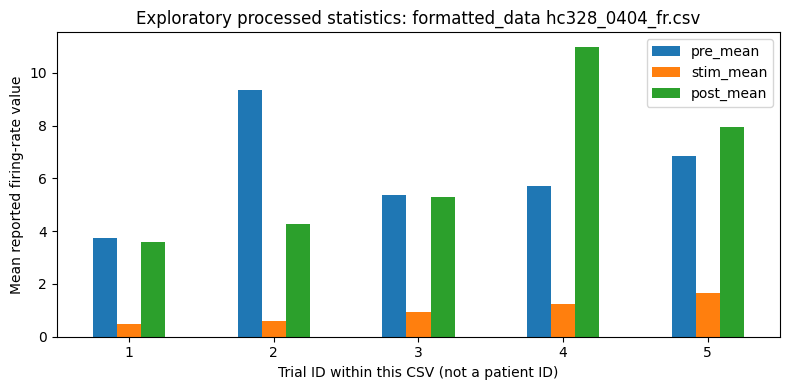

In [6]:
trial_summaries=[]
for n in repo_names:
    if '/data/statistics/' not in n or not n.lower().endswith('fr.csv'): continue
    df=pd.read_csv(io.BytesIO(repo.read(n)))
    if not set(['Neuron_ID','Trial','Condition','Firing_Rate']).issubset(df.columns): continue
    df=df.copy(); df['Firing_Rate']=pd.to_numeric(df.Firing_Rate,errors='coerce')
    grouped=df.groupby(['Trial','Condition'],dropna=False).Firing_Rate.mean().unstack('Condition')
    for trial, r in grouped.iterrows():
        if not all(k in r.index for k in ('pre','stim','post')): continue
        pre,stim,post=r['pre'],r['stim'],r['post']
        trial_summaries.append(dict(
            source_csv=n.split('/')[-1], trial_id_within_csv=str(trial),
            pre_mean=pre,stim_mean=stim,post_mean=post,
            relative_stim_change=(stim-pre)/pre if pd.notna(pre) and pre > 1e-6 else np.nan,
            note='Local processed trial only; no NWB timestamp/action join verified'))
trials=pd.DataFrame(trial_summaries)
trials.to_csv(OUT/'exploratory_trial_means_NOT_SAMPLING_INDEPENDENT.csv',index=False)
print('Processed firing-rate files:',sum(n.endswith('fr.csv') and '/data/statistics/' in n for n in repo_names))
print('Descriptive trial rows:',len(trials),'(NOT independent samples)')
if not trials.empty:
    file_pick = 'formatted_data hc328_0404_fr.csv'
    group=trials[trials.source_csv == file_pick]
    if group.empty: group=trials[trials.source_csv==trials.iloc[0].source_csv]
    display(group[['source_csv','trial_id_within_csv','pre_mean','stim_mean','post_mean','relative_stim_change']])
    chart=group[['pre_mean','stim_mean','post_mean']].copy()
    chart.index=group.trial_id_within_csv
    ax=chart.plot(kind='bar',figsize=(8,4),rot=0)
    ax.set_xlabel('Trial ID within this CSV (not a patient ID)')
    ax.set_ylabel('Mean reported firing-rate value')
    ax.set_title('Exploratory processed statistics: '+group.iloc[0].source_csv)
    plt.tight_layout(); plt.savefig(OUT/'processed_pre_stim_post_exploratory.png',dpi=180);plt.show()

## 7. Retrieve the version-pinned DANDI NWB asset manifest

This requests a small JSON list, **not** the 192-GB dataset. Maps each recording to the published donor/slice reference.

In [7]:
PUBLISHED = [
    ('1A','A','none'),('2B','B','ChR2'),('3C','C','HcKCR1'),('4C','C','ChR2'),
    ('5C','C','HcKCR1'),('6C','C','none'),('7D','D','HcKCR1'),('8D','D','HcKCR1'),
    ('9E','E','HcKCR1'),('10F','F','HcKCR1'),('11G','G','HcKCR1'),('12G','G','HcKCR1')]
reference=pd.DataFrame(PUBLISHED,columns=['slice_id','donor_id','opsin'])

endpoint=f'{API}/dandisets/{DANDISET}/versions/{VERSION}/assets/'
items=[];next_url=endpoint
with requests.Session() as session:
    while next_url:
        resp=session.get(next_url,params={'page_size':100} if next_url==endpoint else None,timeout=60)
        resp.raise_for_status(); payload=resp.json()
        items.extend(payload.get('results',[]));next_url=payload.get('next')
manifest_rows=[]
for a in items:
    match=re.match(r'^sub-(\d+[A-Z])-(\d+)/',a.get('path',''))
    if not match: continue
    manifest_rows.append(dict(asset_id=a['asset_id'],path=a['path'],size_bytes=int(a.get('size',0)),slice_id=match.group(1),file_index=int(match.group(2))))
manifest=pd.DataFrame(manifest_rows).merge(reference,on='slice_id',how='left',validate='many_to_one')
assert not manifest.empty and manifest.asset_id.is_unique
manifest.to_csv(OUT/'manifest_with_slice_and_donor.csv',index=False)
print('NWB recordings:',len(manifest),'Biological slices:',manifest.slice_id.nunique(),'Donors:',manifest.donor_id.nunique())
print('Remote archive volume (GB):',round(manifest.size_bytes.sum()/1e9,2))
print('HcKCR1 slices:',manifest.loc[manifest.opsin.eq('HcKCR1'),'slice_id'].nunique())
if len(manifest)!=69: print('WARNING: Manifest count has changed from the previous Phase 0 audit. Investigate before claiming 69.')

NWB recordings: 69 Biological slices: 12 Donors: 7
Remote archive volume (GB): 192.37
HcKCR1 slices: 8


## 8. Select NWB recordings for remote **metadata-only** inspection

Default: one *small* NWB per inhibitory-opsin slice (8 slices across 5 donors), including slices 3C, 5C, 7D, 8D, 9E, 10F, 11G, 12G. To inspect all assets, set `SCAN_ALL_NWB = True` above. Neither mode loads entire voltage arrays.

In [8]:
if SCAN_ALL_NWB:
    selected=manifest.sort_values(['slice_id','file_index']).reset_index(drop=True)
else:
    selected=(manifest[manifest.opsin.eq('HcKCR1')]
              .sort_values('size_bytes')
              .groupby('slice_id',as_index=False)
              .head(1)
              .sort_values('slice_id')
              .head(MAX_NWB_PROBES)
              .reset_index(drop=True))
selected.to_csv(OUT/'nwb_probe_targets.csv',index=False)
print('Files to probe:',len(selected))
display(selected[['slice_id','donor_id','file_index','size_bytes','path']])

Files to probe: 8


,slice_id,donor_id,file_index,size_bytes,path
0,10F,F,1,1768928157,sub-10F-1/sub-10F-1_ses-20240928T165018_ecephy...
1,11G,G,0,2284244655,sub-11G-0/sub-11G-0_ses-20240928T192015_ecephy...
2,12G,G,0,2508136263,sub-12G-0/sub-12G-0_ses-20240928T165425_ecephy...
3,3C,C,2,751396444,sub-3C-2/sub-3C-2_ses-20240928T192008_ecephys.nwb
4,5C,C,1,571984812,sub-5C-1/sub-5C-1_ses-20240928T165106_ecephys.nwb
5,7D,D,7,924440660,sub-7D-7/sub-7D-7_ses-20240928T165241_ecephys.nwb
6,8D,D,3,2592066492,sub-8D-3/sub-8D-3_ses-20240928T165422_ecephys.nwb
7,9E,E,1,1891062258,sub-9E-1/sub-9E-1_ses-20240928T165422_ecephys.nwb


## 9. Inspect NWB structure and explicit optical-event candidates

We read names, shapes, attributes and small text/scalar metadata. **We never read** `/acquisition/ElectricalSeries/data` voltage arrays. The existence of an empty `/stimulus` container is *not* evidence that trials are labeled.

In [9]:
import h5py
import remfile

STIM_NAME_RE = re.compile(r'gpio|opto|optic|light|laser|led|photostim|trigger|digital|ttl',re.I)

def scalar_text(ds,max_chars=220):
    try:
        if isinstance(ds,h5py.Dataset) and ds.shape==():
            value=ds[()]
            if isinstance(value,bytes): return value.decode('utf8','replace')[:max_chars]
            return str(value)[:max_chars]
    except Exception as exc:
        return 'read_failed:'+repr(exc)[:100]
    return None

def asset_download_url(asset_id):
    r=requests.get(f'{API}/assets/{asset_id}/download/',allow_redirects=True,stream=True,timeout=60)
    try:
        r.raise_for_status()
        if '/assets/' in r.url and r.url.endswith('/download/'):
            raise RuntimeError('Download endpoint did not redirect to byte content')
        return r.url
    finally:
        r.close()

def survey_nwb(asset):
    report=dict(asset_id=asset['asset_id'],path=asset['path'],slice_id=asset['slice_id'],donor_id=asset['donor_id'],status='failed',error='',explicit_event_candidate_count=0,verified_event_count=0,notes='',stim_presentation_items='',interval_table_names='',acquisition_series='',processing_groups='',root_keys='',NWB_subject_id='')
    rf=None
    try:
        rf=remfile.File(url=asset_download_url(asset['asset_id']))
        with h5py.File(rf,'r') as h:
            report['root_keys']='|'.join(h.keys())
            report['stim_presentation_items']='|'.join(h['/stimulus/presentation'].keys()) if '/stimulus/presentation' in h else ''
            report['stim_template_items']='|'.join(h['/stimulus/templates'].keys()) if '/stimulus/templates' in h else ''
            report['interval_table_names']='|'.join(h['/intervals'].keys()) if '/intervals' in h else ''
            report['acquisition_series']='|'.join(h['/acquisition'].keys()) if '/acquisition' in h else ''
            report['processing_groups']='|'.join(h['/processing'].keys()) if '/processing' in h else ''
            report['NWB_subject_id']=scalar_text(h['/general/subject/subject_id']) if '/general/subject/subject_id' in h else ''
            report['session_description']=scalar_text(h['/session_description']) if '/session_description' in h else ''
            report['experiment_description']=scalar_text(h['/general/experiment_description']) if '/general/experiment_description' in h else ''
            if '/acquisition/ElectricalSeries/data' in h:
                d=h['/acquisition/ElectricalSeries/data']
                report['data_shape']=str(tuple(d.shape))
                report['data_dtype']=str(d.dtype)
            if '/acquisition/ElectricalSeries/starting_time' in h:
                st=h['/acquisition/ElectricalSeries/starting_time']
                report['recording_start_offset']=scalar_text(st)
                if 'rate' in st.attrs:
                    rate=st.attrs['rate'];report['sample_rate_hz']=str(rate)
            # Only scan named objects inside relevant data branches; cap recursion and prohibit voltage reads.
            hits=[]
            scanned=0
            def visit(group,path,depth):
                nonlocal scanned
                if scanned>=500 or depth>4 or not isinstance(group,h5py.Group): return
                for k in list(group.keys())[:100]:
                    if scanned>=500: break
                    scanned+=1
                    p=path.rstrip('/')+'/'+k
                    if STIM_NAME_RE.search(k):
                        try:
                            obj=group[k]
                            sh=str(tuple(obj.shape)) if isinstance(obj,h5py.Dataset) else 'Group'
                            hits.append({'path':p,'shape':sh})
                        except Exception as e: hits.append({'path':p,'error':str(e)[:100]})
                    try:
                        obj=group[k]
                        if isinstance(obj,h5py.Group): visit(obj,p,depth+1)
                    except Exception: pass
            for branch in ['/acquisition','/stimulus','/intervals','/processing','/analysis','/general/optogenetics']:
                if branch in h: visit(h[branch],branch,0)
            report['explicit_named_candidates']=json.dumps(hits[:30])
            report['explicit_event_candidate_count']=len(hits)
            report['verified_event_count']=0   # metadata names alone do NOT verify GPIO edge timestamps or dose.
            report['scan_object_limit_reached']=scanned>=500
            report['status']='opened_metadata_only'
            report['notes']='No electrical data arrays loaded. Candidate labels require manual timestamp/value verification.'
    except Exception as exc:
        report['error']=repr(exc)[:600]
    finally:
        if rf is not None:
            try:rf.close()
            except Exception:pass
    return report

results=[]
for k,a in enumerate(selected.to_dict('records'),start=1):
    print(f'[{k}/{len(selected)}] Metadata: {a["slice_id"]}, recording {a["file_index"]} ...',flush=True)
    res=survey_nwb(a)
    print('  ->',res['status'],'optical-named objects:',res['explicit_event_candidate_count'], ' ',res.get('error','')[:100],flush=True)
    results.append(res)
probe_df=pd.DataFrame(results)
probe_df.to_csv(OUT/'nwb_phase0b_metadata_probe.csv',index=False)
display(probe_df[['slice_id','donor_id','status','stim_presentation_items','interval_table_names','explicit_event_candidate_count','verified_event_count','error']])

[1/8] Metadata: 10F, recording 1 ...
  -> opened_metadata_only optical-named objects: 0   
[2/8] Metadata: 11G, recording 0 ...
  -> opened_metadata_only optical-named objects: 0   
[3/8] Metadata: 12G, recording 0 ...
  -> opened_metadata_only optical-named objects: 0   
[4/8] Metadata: 3C, recording 2 ...
  -> opened_metadata_only optical-named objects: 0   
[5/8] Metadata: 5C, recording 1 ...
  -> opened_metadata_only optical-named objects: 0   
[6/8] Metadata: 7D, recording 7 ...
  -> opened_metadata_only optical-named objects: 0   
[7/8] Metadata: 8D, recording 3 ...
  -> opened_metadata_only optical-named objects: 0   
[8/8] Metadata: 9E, recording 1 ...
  -> opened_metadata_only optical-named objects: 0   


,slice_id,donor_id,status,stim_presentation_items,interval_table_names,explicit_event_candidate_count,verified_event_count,error
0,10F,F,opened_metadata_only,,,0,0,
1,11G,G,opened_metadata_only,,,0,0,
2,12G,G,opened_metadata_only,,,0,0,
3,3C,C,opened_metadata_only,,,0,0,
4,5C,C,opened_metadata_only,,,0,0,
5,7D,D,opened_metadata_only,,,0,0,
6,8D,D,opened_metadata_only,,,0,0,
7,9E,E,opened_metadata_only,,,0,0,


## 10. Conclude precisely what is and is not recoverable

Interpret the audit conservatively. A *successful remote open* is not the same as *verified synchronized optical trials*. Output flags show whether model training can start **without reconstructing missing labels**.

In [10]:
opened=int((probe_df.status=='opened_metadata_only').sum())
failed=int((probe_df.status!='opened_metadata_only').sum())
candidates=int((probe_df.explicit_event_candidate_count.fillna(0)>0).sum())
summary={
 'timestamp_utc':datetime.now(timezone.utc).isoformat(),
 'dandiset':DANDISET,'version':VERSION,
 'n_nwb_files_manifest':len(manifest),
 'n_independent_donors_published':7,
 'n_biological_slices_published':12,
 'n_inhibitory_slices_published':8,
 'n_nwb_metadata_probed':len(probe_df),
 'n_nwb_opened':opened,
 'n_nwb_probe_failed':failed,
 'n_nwb_with_named_optical_candidates':candidates,
 'n_nwb_with_verified_aligned_optical_trials':0,
 'repository_statistics_csv_count':int((repo_inventory.evidence_type=='processed_response_statistics').sum()),
 'repository_stimulation_example_count':int((repo_inventory.evidence_type=='stimulation_log_example').sum()),
 'training_readiness':'NOT READY for supervised intervention-response time series without verified event-to-NWB mapping',
 'next_step':'Inspect named candidates if any; otherwise request corresponding original GPIO timestamps, stimulation logs, and raw-to-NWB mapping from authors.'
}
(OUT/'phase0b_decision.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))
notes="""Research data request checklist (not an email sent automatically)
1. For each DANDI NWB asset ID, provide original raw MaxWell .raw.h5 recording basename/UUID and donor/slice mapping.
2. Provide measured GPIO transition/edge timestamps within each recording, or timestamped optical-event CSV in NWB-relative seconds.
3. Provide matching experiment-specific *_opto_stim_log.csv with requested intensity, duration, wavelength and calibration/LED settings.
4. Explain how timestamps in experiment log align with recording acquisition clock, including possible offsets/jitter.
5. Provide challenge-medium change time windows and protocol/condition labels for each recording.
6. Provide curated spike trains/Kilosort outputs if publicly releasable; otherwise explain how to reproduce them.
7. Confirm permission/access terms and whether new NWB files with optical TimeSeries/interval annotations are available.
Important: Do not assume all NWBs have stimulation; need negative/control recording labels.
"""
(OUT/'author_metadata_request_checklist.txt').write_text(notes)
print('\nSTUDY DECISION:')
if candidates:
 print('Possible named optical data objects found: inspect timestamp/value data carefully before any join or training.')
else:
 print('No explicitly named optical events discovered in the inspected NWBs. This does not prove absence in uninspected files.')
print('First useful ML target after verified labels: matched PRE/STIM/POST neural response, then time-series prediction.')

{
  "timestamp_utc": "2026-10-09T21:41:09.009196+00:00",
  "dandiset": "001132",
  "version": "0.241130.1903",
  "n_nwb_files_manifest": 69,
  "n_independent_donors_published": 7,
  "n_biological_slices_published": 12,
  "n_inhibitory_slices_published": 8,
  "n_nwb_metadata_probed": 8,
  "n_nwb_opened": 8,
  "n_nwb_probe_failed": 0,
  "n_nwb_with_named_optical_candidates": 0,
  "n_nwb_with_verified_aligned_optical_trials": 0,
  "repository_statistics_csv_count": 26,
  "repository_stimulation_example_count": 2,
  "training_readiness": "NOT READY for supervised intervention-response time series without verified event-to-NWB mapping",
  "next_step": "Inspect named candidates if any; otherwise request corresponding original GPIO timestamps, stimulation logs, and raw-to-NWB mapping from authors."
}

STUDY DECISION:
No explicitly named optical events discovered in the inspected NWBs. This does not prove absence in uninspected files.
First useful ML target after verified labels: matched PRE/S

## 11. Download all results as one ZIP

Download `phase0b_optogenetics_results.zip` from `/kaggle/working` and upload it to this chat. Include the notebook error screenshot if any cells fail.

**After we receive the results:**
1. If trustworthy ON/OFF times and actions exist: construct supervised response training pairs.
2. If actions are missing but pre/stim/post summaries are valid: reproduce response statistics only.
3. If GPIO events and logs are unavailable: request the original matching data from Andrews et al. and work in parallel on independent preprocessing/spike-detection baselines.


In [11]:
zip_path = OUT.parent/'phase0b_optogenetics_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    for f in sorted(OUT.iterdir()):
        if f.is_file() and f!=REPO_PATH:
            archive.write(f,arcname=f.name)
print('Ready:',zip_path)
print('Size:',round(zip_path.stat().st_size/1024,1),'KB')
print('Upload this ZIP here; no 192-GB raw dataset is required.')

Ready: /kaggle/working/phase0b_optogenetics_results.zip
Size: 56.9 KB
Upload this ZIP here; no 192-GB raw dataset is required.
